# **Sequential Fixed-Width Confidence Interval Estimation**

Experiment: We want to measure the average height of male adults in Mauritius. Let us assume that their heights are normally distributed in the population $\mathcal{P} = [x_1, x_2, ..., x_N]$. We create the population, 

In [154]:
# Importing,
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

N = 600000
mu, sigma = 173, 7
pop = np.random.normal(loc=mu, scale=sigma, size=N)

Now we create a random sample $\mathcal{S}$ with $n=1000$ number of measurements from the population,

In [155]:
n = 1000
sample = np.random.choice(pop, size=n, replace=True)

Creating a function to compute the estimator for the population variance $\hat{s}_n$

Halting Size: 736, Epsilon: 0.4996609180198701


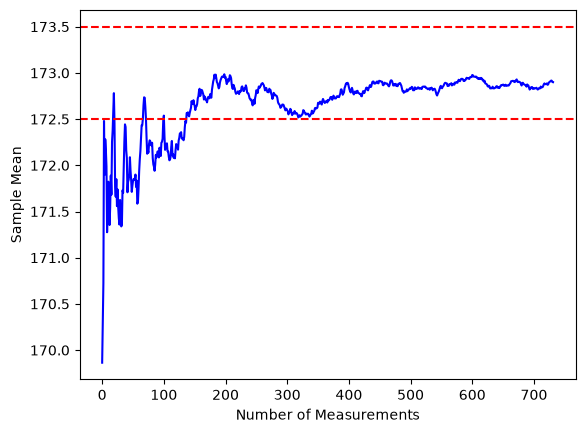

In [156]:
# PARAMETERS,
m=1.96
epsilon = 0.5
n_min = 5

# Running the experiment,
means = []
stds = []
for i in range(n_min, n):

    epsilon_current = (m*np.std(sample[:i], ddof=1))/np.sqrt(i)
    means.append(np.mean(sample[:i]).item())
    stds.append(np.std(sample[:i], ddof=1).item())

    if epsilon_current <= epsilon:
        print(f"Halting Size: {i}, Epsilon: {epsilon_current}")
        halting_size = i
        break

# Visualising,
plt.plot(means, color="blue")
plt.axhline(y=mu+epsilon, linestyle="--", color="red")
plt.axhline(y=mu-epsilon, linestyle="--", color="red")
plt.xlabel("Number of Measurements")
plt.ylabel("Sample Mean")
plt.show()

### 2. Running The Experiments

Packing the experiment into a helper function,

In [157]:
def run_experiment(population, n_trials, m, epsilon, n, n_min):
    """Helper function to run the experiment for multiple trials and collect results."""

    experiment_results = {"halting_size": [], "mean": [], "std": []}
    for trial in range(n_trials):
        # Creating sample,
        sample = np.random.choice(population, size=n, replace=True)

        # Sequentially checking halting condition,
        for i in range(n_min, n):
            epsilon_current = (m*np.std(sample[:i], ddof=1))/np.sqrt(i)
            if epsilon_current <= epsilon:
                experiment_results["halting_size"].append(i)
                break

        # Computing stats,
        experiment_results["mean"].append(np.mean(sample[:i]).item())
        experiment_results["std"].append(np.std(sample[:i], ddof=1).item())
    return experiment_results

Now we finally run the experiment,

In [ ]:
# PARAMETERS,
n_trials=2500
n=1000
m=1.96 # 95% confidence interval.
epsilon = 0.5 # Nearest cm.
n_min = 50 # Minimum sample size.

results = run_experiment(pop, n_trials, m, epsilon, n, n_min)
df = pd.DataFrame(results)

Visualising the distribution of halting times,

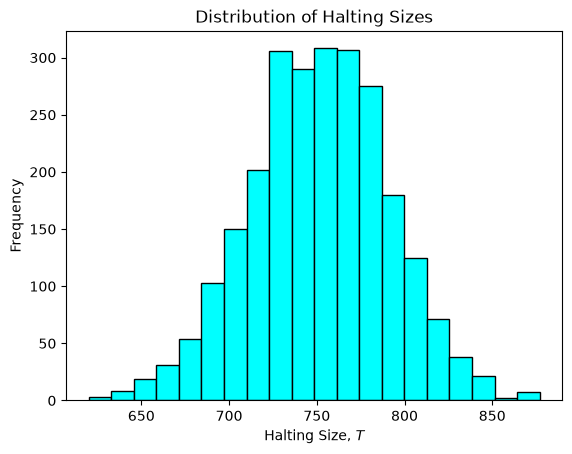

In [149]:
plt.hist(results["halting_size"], bins=20, edgecolor="black", color="cyan")
plt.xlabel("Halting Size, $T$")
plt.ylabel("Frequency")
plt.title("Distribution of Halting Sizes")
plt.show()

Checking if confidence interval is met,

In [150]:
prob = 1 - np.mean(np.abs(np.array(results["mean"]) - mu) >= epsilon)
prob.item()

0.9452